# Comptage de mots : Python vs Hadoop MapReduce

**Cours** : Fondements et Applications du Big Data — TP 1
**Auteur** : Antoine Chiausa

## Introduction

On compte les occurrences de chaque mot d'un fichier avec trois méthodes, sur trois tailles de fichier (Ko, Mo, Go), et on compare leurs temps d'exécution :

| # | Méthode | Exécution |
|---|---|---|
| 1 | **Python simple** : un dictionnaire, une boucle | 1 processus, tout en mémoire |
| 2 | **Pseudo-MapReduce Python** : `mapper` → `shuffle` → `reducer` | 1 processus, tout en mémoire |
| 3 | **Hadoop MapReduce** : job `wordcount` sur HDFS + YARN | plusieurs tâches *map* en parallèle, données lues par blocs |

**Question** : à partir de quelle taille le surcoût de Hadoop devient-il rentable, voire indispensable ?

## 1. Environnement

Hadoop tourne ici en mode **pseudo-distribué** : les démons HDFS (NameNode, DataNode) et YARN (ResourceManager, NodeManager) s'exécutent tous sur la même machine. C'est un vrai cluster Hadoop, mais à un seul nœud.

In [32]:
import getpass, os, platform, re, shutil, subprocess, sys, time, urllib.request
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import psutil

HADOOP_VERSION = "3.5.0"
HADOOP_HOME = Path.home() / f"hadoop-{HADOOP_VERSION}"   # chemin sans espace (exigé par les scripts Hadoop)
HADOOP_DATA = Path.home() / "hadoop-data"                # stockage local de HDFS
JAVA_HOME = subprocess.run(["/usr/libexec/java_home", "-v", "17"], capture_output=True, text=True).stdout.strip()

os.environ["JAVA_HOME"] = JAVA_HOME
os.environ["HADOOP_HOME"] = str(HADOOP_HOME)
os.environ["PATH"] = f"{HADOOP_HOME}/bin:{os.environ['PATH']}"

DATA, SCRIPTS, OUT, LOGS = Path("data"), Path("scripts"), Path("resultats"), Path("logs")
for d in (DATA, SCRIPTS, OUT, LOGS):
    d.mkdir(exist_ok=True)

RAM = psutil.virtual_memory().total
print(f"Machine : {platform.machine()}, {os.cpu_count()} cœurs, {RAM / 2**30:.0f} Go de RAM")
print(f"Python  : {platform.python_version()}")
print(f"Java    : {JAVA_HOME}")

Machine : arm64, 8 cœurs, 16 Go de RAM
Python  : 3.14.8
Java    : /Library/Java/JavaVirtualMachines/jdk-17.jdk/Contents/Home


### Installation de Hadoop

Téléchargement de l'archive officielle (une seule fois), puis vérification.

In [11]:
if not HADOOP_HOME.exists():
    url = f"https://dlcdn.apache.org/hadoop/common/hadoop-{HADOOP_VERSION}/hadoop-{HADOOP_VERSION}.tar.gz"
    subprocess.run(f"curl -sL --fail {url} | tar -xz -C {Path.home()}", shell=True, check=True)

print(subprocess.run(["hadoop", "version"], capture_output=True, text=True).stdout.splitlines()[0])

Hadoop 3.5.0


### Configuration pseudo-distribuée

Quatre fichiers XML dans `$HADOOP_HOME/etc/hadoop`. Les réglages importants :

- `fs.defaultFS` : les chemins pointent vers HDFS (et non le disque local) ;
- `dfs.replication = 1` : un seul DataNode, donc une seule copie de chaque bloc ;
- `mapreduce.framework.name = yarn` : les jobs sont orchestrés par YARN ;
- seuil d'occupation disque du NodeManager relevé à 99 % (par défaut, un disque rempli à plus de 90 % rend le nœud *unhealthy* et les jobs restent bloqués).

In [58]:
def ecrire_config(fichier, proprietes):
    props = "\n".join(f"  <property><name>{k}</name><value>{v}</value></property>" for k, v in proprietes.items())
    (HADOOP_HOME / "etc/hadoop" / fichier).write_text(f"<?xml version=\"1.0\"?>\n<configuration>\n{props}\n</configuration>\n")

env_mr = f"HADOOP_MAPRED_HOME={HADOOP_HOME}"

ecrire_config("core-site.xml", {
    "fs.defaultFS": "hdfs://localhost:8020",
    "hadoop.tmp.dir": HADOOP_DATA,
})
ecrire_config("hdfs-site.xml", {
    "dfs.replication": 1,
})
ecrire_config("mapred-site.xml", {
    "mapreduce.framework.name": "yarn",
    "yarn.app.mapreduce.am.env": env_mr,
    "mapreduce.map.env": env_mr,
    "mapreduce.reduce.env": env_mr,
})
ecrire_config("yarn-site.xml", {
    "yarn.nodemanager.aux-services": "mapreduce_shuffle",
    "yarn.nodemanager.resource.memory-mb": 8192,
    "yarn.nodemanager.resource.cpu-vcores": os.cpu_count(),
    "yarn.nodemanager.vmem-check-enabled": "false",
    "yarn.nodemanager.disk-health-checker.max-disk-utilization-per-disk-percentage": 99,
})

### Démarrage du cluster

Les démons sont lancés un par un avec `--daemon start` (équivalent de `start-dfs.sh` / `start-yarn.sh` du cours, mais sans passer par SSH).

In [59]:
def sh(*cmd, verifier=True):
    "Exécute une commande, l'affiche, et renvoie sa sortie standard."
    cmd = [str(c) for c in cmd]
    print("$", " ".join(cmd))
    r = subprocess.run(cmd, capture_output=True, text=True)
    if verifier and r.returncode != 0:
        raise RuntimeError(r.stderr[-2000:])
    return r.stdout

def attendre(cmd, motif, delai=120):
    "Relance cmd jusqu'à ce que sa sortie contienne motif."
    fin = time.time() + delai
    while time.time() < fin:
        r = subprocess.run(cmd, capture_output=True, text=True)
        if re.search(motif, r.stdout + r.stderr):
            return
        time.sleep(2)
    raise TimeoutError(f"{' '.join(cmd)} : '{motif}' introuvable")

if not (HADOOP_DATA / "dfs/name/current").exists():       # premier lancement uniquement
    sh("hdfs", "namenode", "-format", "-nonInteractive")

for outil, demon in [("hdfs", "namenode"), ("hdfs", "datanode"), ("yarn", "resourcemanager"), ("yarn", "nodemanager")]:
    sh(outil, "--daemon", "start", demon, verifier=False)  # sans effet si déjà démarré

attendre(["hdfs", "dfsadmin", "-safemode", "get"], "Safe mode is OFF")
attendre(["hdfs", "dfsadmin", "-report"], r"Live datanodes \(1\)")
attendre(["yarn", "node", "-list"], "RUNNING")
print(subprocess.run([f"{JAVA_HOME}/bin/jps"], capture_output=True, text=True).stdout)

$ hdfs --daemon start namenode
$ hdfs --daemon start datanode
$ yarn --daemon start resourcemanager
$ yarn --daemon start nodemanager
11041 DataNode
10929 NameNode
11153 ResourceManager
12885 Jps
11262 NodeManager



## 2. Les trois méthodes

### Méthode 1 — Python simple

Tout le fichier est lu en mémoire, puis une boucle met à jour un dictionnaire `mot → compteur`.

In [14]:
%%writefile scripts/wordcount_simple.py
import sys

def compter_occurrences(fichier):
    with open(fichier, "r", encoding="utf-8") as f:
        mots = f.read().split()

    compteur = {}
    for mot in mots:
        compteur[mot] = compteur.get(mot, 0) + 1
    return compteur

if __name__ == "__main__":
    resultats = compter_occurrences(sys.argv[1])
    for mot, nb in sorted(resultats.items(), key=lambda x: x[1], reverse=True):
        print(f"{mot} : {nb}")

Overwriting scripts/wordcount_simple.py


### Méthode 2 — Pseudo-MapReduce Python

Mêmes étapes que MapReduce, mais dans un seul processus :

1. **map** : chaque ligne devient une liste de paires `(mot, 1)` ;
2. **shuffle** : les paires sont regroupées par clé → `mot → [1, 1, 1, …]` ;
3. **reduce** : chaque liste est agrégée par une somme.

In [15]:
%%writefile scripts/wordcount_pseudo_mr.py
import sys
from collections import defaultdict

def mapper(ligne):
    mots = ligne.strip().split()
    return [(mot, 1) for mot in mots]

def shuffle(mapped_data):
    grouped = defaultdict(list)
    for mot, valeur in mapped_data:
        grouped[mot].append(valeur)
    return grouped

def reducer(grouped_data):
    reduced = {}
    for mot, valeurs in grouped_data.items():
        reduced[mot] = sum(valeurs)
    return reduced

if __name__ == "__main__":
    mapped = []
    with open(sys.argv[1], "r", encoding="utf-8") as f:
        for ligne in f:
            mapped.extend(mapper(ligne))

    grouped = shuffle(mapped)
    reduced = reducer(grouped)

    for mot, count in sorted(reduced.items(), key=lambda x: x[1], reverse=True):
        print(f"{mot} : {count}")

Overwriting scripts/wordcount_pseudo_mr.py


### Méthode 3 — Hadoop MapReduce

On utilise le job `wordcount` fourni avec Hadoop (`hadoop-mapreduce-examples`). Même logique que la méthode 2, mais réellement distribuée :

- le fichier est stocké dans **HDFS**, découpé en blocs de 128 Mo ;
- **YARN** lance une tâche *map* par bloc, en parallèle ; chacune émet des paires `(mot, 1)` ;
- un *combiner* pré-agrège les paires dans chaque tâche *map*, ce qui réduit le volume à transférer ;
- le *shuffle* trie et regroupe par mot, puis la tâche *reduce* fait la somme.

Chaque tâche lit son bloc en flux : la mémoire utilisée ne dépend pas de la taille totale du fichier.

In [16]:
JAR = HADOOP_HOME / f"share/hadoop/mapreduce/hadoop-mapreduce-examples-{HADOOP_VERSION}.jar"
HDFS = f"/user/{getpass.getuser()}/wordcount"

### Protocole de mesure

- Chaque méthode est lancée comme un **processus séparé** et chronométrée de bout en bout (comme `time python …` dans le cours), démarrage et affichage du résultat compris.
- On relève aussi le **pic de mémoire** des processus Python.
- **Garde-fou** : un processus qui dépasse 60 % de la RAM (ou 30 min) est arrêté et noté en échec. Au-delà, la machine se met à *swapper* et la mesure n'a plus de sens.
- Pour Hadoop, le temps mesuré est celui du job (`hadoop jar …`) ; le chargement dans HDFS (`hdfs dfs -put`) est chronométré à part.
- Chaque résultat est **vérifié** contre le comptage attendu.

In [17]:
LIMITE_RAM = 0.6 * RAM      # octets
TIMEOUT = 30 * 60           # secondes
mesures = []                # une entrée par (jeu, méthode)

def mesurer(cmd, sortie=os.devnull, journal=os.devnull):
    "Exécute cmd ; renvoie (statut, durée en s, pic mémoire en octets)."
    with open(sortie, "w") as out, open(journal, "w") as err:
        t0 = time.perf_counter()
        p = subprocess.Popen([str(c) for c in cmd], stdout=out, stderr=err)
        ps, pic, statut = psutil.Process(p.pid), 0, "OK"
        while True:
            pid, etat, usage = os.wait4(p.pid, os.WNOHANG)
            duree = time.perf_counter() - t0
            if pid:
                break
            try:
                pic = max(pic, ps.memory_full_info().uss)
            except psutil.Error:
                pass
            if statut == "OK" and (pic > LIMITE_RAM or duree > TIMEOUT):
                statut = "ÉCHEC mémoire" if pic > LIMITE_RAM else "ÉCHEC timeout"
                p.kill()
            time.sleep(min(0.05, duree / 20))
    p.returncode = os.waitstatus_to_exitcode(etat)
    if statut == "OK" and p.returncode != 0:
        statut = "ERREUR"
    pic = max(pic, usage.ru_maxrss * (1 if sys.platform == "darwin" else 1024))
    return statut, duree, pic

def enregistrer(jeu, methode, statut, duree, **infos):
    mesures[:] = [x for x in mesures if (x["jeu"], x["méthode"]) != (jeu, methode)]   # ré-exécution : on remplace
    mesures.append({"jeu": jeu, "taille (Mo)": fichier(jeu).stat().st_size / 1e6,
                    "méthode": methode, "statut": statut, "temps (s)": duree, **infos})

def executer_python(jeu):
    for methode, script in [("Python simple", "wordcount_simple.py"), ("Pseudo-MapReduce", "wordcount_pseudo_mr.py")]:
        statut, duree, pic = mesurer([sys.executable, SCRIPTS / script, fichier(jeu)],
                                     sortie=OUT / f"{jeu}_{methode}.txt")
        enregistrer(jeu, methode, statut, duree, **{"pic mémoire (Mo)": pic / 1e6})
        print(f"{methode:<17} {statut:<14} {duree:8.3f} s   pic mémoire {pic / 1e6:8.0f} Mo")

def executer_hadoop(jeu):
    entree, sortie = f"{HDFS}/{jeu}/input", f"{HDFS}/{jeu}/output"
    sh("hdfs", "dfs", "-rm", "-r", "-f", "-skipTrash", f"{HDFS}/{jeu}")
    sh("hdfs", "dfs", "-mkdir", "-p", entree)
    t0 = time.perf_counter()
    sh("hdfs", "dfs", "-put", fichier(jeu), entree)
    chargement = time.perf_counter() - t0

    cmd = ["hadoop", "jar", JAR, "wordcount", entree, sortie]
    print("$", " ".join(map(str, cmd)))
    statut, duree, _ = mesurer(cmd, journal=LOGS / f"{jeu}_hadoop.log")
    journal = (LOGS / f"{jeu}_hadoop.log").read_text()
    if statut != "OK":
        print(journal[-2000:])
    else:
        (OUT / f"{jeu}_Hadoop MapReduce.txt").write_text(sh("hdfs", "dfs", "-cat", f"{sortie}/part-r-*"))
    maps = re.search(r"Launched map tasks=(\d+)", journal)
    enregistrer(jeu, "Hadoop MapReduce", statut, duree,
                **{"chargement HDFS (s)": chargement, "tâches map": int(maps.group(1)) if maps else None})
    print(f"\nHadoop MapReduce  {statut}  {duree:.1f} s  (+ {chargement:.1f} s de chargement HDFS, {maps.group(1) if maps else '?'} tâches map)")

def verifier(jeu, methode):
    "Compare le résultat d'une méthode au comptage attendu (comptage du fichier de base × m)."
    obtenu = {}
    for ligne in (OUT / f"{jeu}_{methode}.txt").read_text(encoding="utf-8").splitlines():
        mot, nb = re.fullmatch(r"(\S+)(?: : |\t)(\d+)", ligne).groups()
        obtenu[mot] = int(nb)
    return obtenu == {mot: nb * JEUX[jeu] for mot, nb in REFERENCE.items()}

def comparer(jeu):
    df = pd.DataFrame([x for x in mesures if x["jeu"] == jeu]).drop(columns="jeu").set_index("méthode")
    df["résultat correct"] = [verifier(jeu, m) if s == "OK" else "—" for m, s in df["statut"].items()]
    ok = df[df["statut"] == "OK"]["temps (s)"]
    df["temps / plus rapide"] = (ok / ok.min()).round(1)
    return df.round(3)

## 3. Jeux de données

**Fichier de base** : les mots de l'exemple du cours (§ 3.1), **un mot par ligne**. Les occurrences du cours (85 au total) sont légèrement augmentées pour obtenir un compte rond : **N = 100 lignes** (`words_100.txt`), soit 28 × `chat`, 13 × `chien`, etc.

**Fichiers plus gros** : le fichier de base est **dupliqué m fois** (m × N lignes). Le vocabulaire ne change pas : le comptage attendu vaut exactement *m* fois celui du fichier de base, ce qui permet de vérifier chaque résultat.

| Jeu | m | Lignes (m × N) | Fichier | Taille |
|---|---|---|---|---|
| `petit` | 1 | 100 | `words_100.txt` | 0,6 Ko |
| `moyen` | 10 000 | 1 000 000 | `words_1000000.txt` | 6 Mo |
| `gros` | 4 000 000 | 400 000 000 | `words_400000000.txt` | 2,4 Go |

In [18]:
%%bash
# Fichier de base : chaque mot répété un nombre connu de fois (total : 100)
mkdir -p data && cd data
for p in chat:28 chien:13 arbre:8 fleur:8 maison:6 soleil:6 montagne:6 livre:5 ciel:5 mer:3 lune:3 route:3 oiseau:3 jardin:2 voiture:1
do
  yes "${p%:*}" | head -n "${p#*:}"
done > words_100.txt
wc -l words_100.txt

     100 words_100.txt


In [19]:
N = 100
JEUX = {"petit": 1, "moyen": 10_000, "gros": 4_000_000}     # nom → facteur de duplication m

def fichier(jeu):
    return DATA / f"words_{N * JEUX[jeu]}.txt"

base = fichier("petit").read_text()
REFERENCE = Counter(base.split())                           # comptage attendu pour m = 1
assert sum(REFERENCE.values()) == N

# Duplication m fois (équivalent shell : yes "$(cat words_100.txt)" | head -n $((100*m)) > words_$((100*m)).txt)
for jeu, m in JEUX.items():
    chemin = fichier(jeu)
    if not chemin.exists() or chemin.stat().st_size != len(base) * m:
        assert shutil.disk_usage(".").free > 2.5 * len(base) * m, "Espace disque insuffisant (fichier local + copie HDFS)"
        k = min(m, 100_000)
        with open(chemin, "w") as f:
            for _ in range(m // k):
                f.write(base * k)
            f.write(base * (m % k))
    print(f"{jeu:<6} m = {m:>9,}   {m * N:>11,} lignes   {chemin.stat().st_size / 1e6:>10,.4f} Mo   {chemin.name}".replace(",", " "))

print(f"\n{len(REFERENCE)} mots distincts :", dict(REFERENCE.most_common()))

petit  m =         1           100 lignes       0.0006 Mo   words_100.txt
moyen  m =    10 000     1 000 000 lignes       5.9500 Mo   words_1000000.txt
gros   m = 4 000 000   400 000 000 lignes   2 380.0000 Mo   words_400000000.txt

15 mots distincts : {'chat': 28, 'chien': 13, 'arbre': 8, 'fleur': 8, 'maison': 6, 'soleil': 6, 'montagne': 6, 'livre': 5, 'ciel': 5, 'mer': 3, 'lune': 3, 'route': 3, 'oiseau': 3, 'jardin': 2, 'voiture': 1}


## 4. Petit jeu de données (Ko)

### Python (méthodes 1 et 2)

In [20]:
executer_python("petit")

Python simple     OK                0.049 s   pic mémoire       15 Mo
Pseudo-MapReduce  OK                0.026 s   pic mémoire       15 Mo


### Hadoop MapReduce (méthode 3)

In [21]:
executer_hadoop("petit")

$ hdfs dfs -rm -r -f -skipTrash /user/antoinechiausa/wordcount/petit
$ hdfs dfs -mkdir -p /user/antoinechiausa/wordcount/petit/input
$ hdfs dfs -put data/words_100.txt /user/antoinechiausa/wordcount/petit/input
$ hadoop jar /Users/antoinechiausa/hadoop-3.5.0/share/hadoop/mapreduce/hadoop-mapreduce-examples-3.5.0.jar wordcount /user/antoinechiausa/wordcount/petit/input /user/antoinechiausa/wordcount/petit/output
$ hdfs dfs -cat /user/antoinechiausa/wordcount/petit/output/part-r-*

Hadoop MapReduce  OK  15.0 s  (+ 1.3 s de chargement HDFS, 1 tâches map)


### Comparaison

In [22]:
comparer("petit")

,taille (Mo),statut,temps (s),pic mémoire (Mo),chargement HDFS (s),tâches map,résultat correct,temps / plus rapide
méthode,,,,,,,,
Python simple,0.001,OK,0.049,15.188,NaN,NaN,True,1.9
Pseudo-MapReduce,0.001,OK,0.026,15.303,NaN,NaN,True,1.0
Hadoop MapReduce,0.001,OK,14.950,NaN,1.298,1.0,True,584.3


**Observations** : on voit que Hadoop MapReduce met bien plus de temps que python (**15s** vs **0,049s** ou **0,026s**) ce qui le rend totalement inutile pour des petits jeux de données.

## 5. Jeu de données moyen (Mo)

### Python (méthodes 1 et 2)

In [23]:
executer_python("moyen")

Python simple     OK                0.148 s   pic mémoire       87 Mo
Pseudo-MapReduce  OK                0.414 s   pic mémoire      151 Mo


### Hadoop MapReduce (méthode 3)

In [24]:
executer_hadoop("moyen")

$ hdfs dfs -rm -r -f -skipTrash /user/antoinechiausa/wordcount/moyen
$ hdfs dfs -mkdir -p /user/antoinechiausa/wordcount/moyen/input
$ hdfs dfs -put data/words_1000000.txt /user/antoinechiausa/wordcount/moyen/input
$ hadoop jar /Users/antoinechiausa/hadoop-3.5.0/share/hadoop/mapreduce/hadoop-mapreduce-examples-3.5.0.jar wordcount /user/antoinechiausa/wordcount/moyen/input /user/antoinechiausa/wordcount/moyen/output
$ hdfs dfs -cat /user/antoinechiausa/wordcount/moyen/output/part-r-*

Hadoop MapReduce  OK  14.5 s  (+ 0.9 s de chargement HDFS, 1 tâches map)


### Comparaison

In [25]:
comparer("moyen")

,taille (Mo),statut,temps (s),pic mémoire (Mo),chargement HDFS (s),tâches map,résultat correct,temps / plus rapide
méthode,,,,,,,,
Python simple,5.95,OK,0.148,86.524,NaN,NaN,True,1.0
Pseudo-MapReduce,5.95,OK,0.414,151.126,NaN,NaN,True,2.8
Hadoop MapReduce,5.95,OK,14.533,NaN,0.853,1.0,True,98.4


**Observations** : même observations que précédemment

## 6. Gros jeu de données (Go)

### Python (méthodes 1 et 2)

In [26]:
executer_python("gros")

Python simple     OK              192.112 s   pic mémoire     4177 Mo
Pseudo-MapReduce  ERREUR         1396.704 s   pic mémoire     6476 Mo


### Hadoop MapReduce (méthode 3)

In [27]:
executer_hadoop("gros")

$ hdfs dfs -rm -r -f -skipTrash /user/antoinechiausa/wordcount/gros
$ hdfs dfs -mkdir -p /user/antoinechiausa/wordcount/gros/input
$ hdfs dfs -put data/words_400000000.txt /user/antoinechiausa/wordcount/gros/input
$ hadoop jar /Users/antoinechiausa/hadoop-3.5.0/share/hadoop/mapreduce/hadoop-mapreduce-examples-3.5.0.jar wordcount /user/antoinechiausa/wordcount/gros/input /user/antoinechiausa/wordcount/gros/output
$ hdfs dfs -cat /user/antoinechiausa/wordcount/gros/output/part-r-*

Hadoop MapReduce  OK  83.6 s  (+ 13.5 s de chargement HDFS, 18 tâches map)


### Comparaison

In [28]:
comparer("gros")

,taille (Mo),statut,temps (s),pic mémoire (Mo),chargement HDFS (s),tâches map,résultat correct,temps / plus rapide
méthode,,,,,,,,
Python simple,2380.0,OK,192.112,4176.658,NaN,NaN,True,2.3
Pseudo-MapReduce,2380.0,ERREUR,1396.704,6475.661,NaN,NaN,—,NaN
Hadoop MapReduce,2380.0,OK,83.553,NaN,13.454,18.0,True,1.0


**Observations** : on voit que le Pseudo-MapReduce en python a été arrêté après **plus de 30 minutes** (conformément à la règle du garde-fou en début de notebook) à tourner. Pour des gros jeux de données (de l'ordre des centaines de Mo voire de Go) alors Hadoop MapReduce est beaucoup plus efficace (**83 secondes**) que nimporte quel algorithme python (le plus rapide ici fait autour de **200 secondes**)

## 7. Synthèse

Temps d'exécution des trois méthodes en fonction de la taille du fichier.

In [29]:
df = pd.DataFrame(mesures)
df.loc[df["statut"] != "OK", "temps (s)"] = float("nan")        # un échec n'a pas de temps d'exécution
df["débit (Mo/s)"] = df["taille (Mo)"] / df["temps (s)"]

synthese = df.pivot(index=["jeu", "taille (Mo)"], columns="méthode", values=["temps (s)", "débit (Mo/s)"]).sort_index(level=1)
synthese.round(2).fillna("échec")

temps (s)                                 \
méthode           Hadoop MapReduce Pseudo-MapReduce Python simple   
jeu   taille (Mo)                                                   
petit 0.000595               14.95             0.03          0.05   
moyen 5.950000               14.53             0.41          0.15   
gros  2380.000000            83.55            échec        192.11   

                      débit (Mo/s)                                 
méthode           Hadoop MapReduce Pseudo-MapReduce Python simple  
jeu   taille (Mo)                                                  
petit 0.000595                0.00             0.02          0.01  
moyen 5.950000                0.41            14.39         40.30  
gros  2380.000000            28.48            échec         12.39

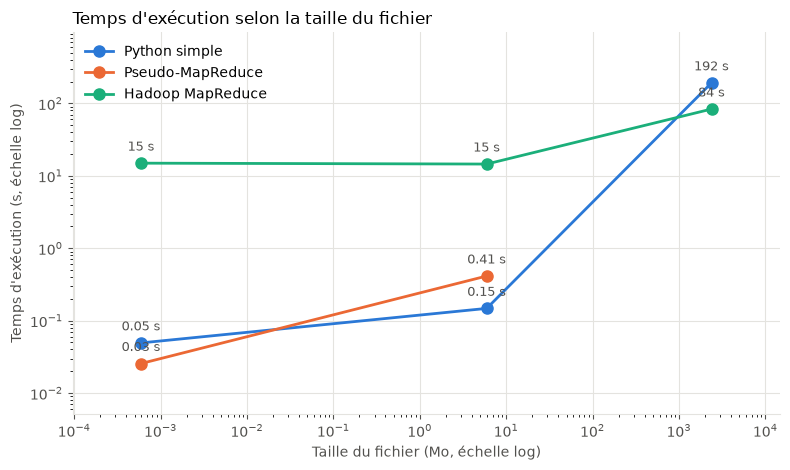

In [30]:
COULEURS = {"Python simple": "#2a78d6", "Pseudo-MapReduce": "#eb6834", "Hadoop MapReduce": "#1baf7a"}
ENCRE, GRILLE = "#52514e", "#e4e3df"

fig, ax = plt.subplots(figsize=(8, 4.8))
for methode, couleur in COULEURS.items():
    s = df[(df["méthode"] == methode) & (df["statut"] == "OK")].sort_values("taille (Mo)")
    ax.plot(s["taille (Mo)"], s["temps (s)"], marker="o", markersize=8, linewidth=2, color=couleur, label=methode)
    for x, y in zip(s["taille (Mo)"], s["temps (s)"]):
        ax.annotate(f"{y:.2f} s" if y < 10 else f"{y:.0f} s", (x, y), textcoords="offset points", xytext=(0, 9),
                    ha="center", fontsize=9, color=ENCRE)

ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Taille du fichier (Mo, échelle log)", color=ENCRE)
ax.set_ylabel("Temps d'exécution (s, échelle log)", color=ENCRE)
ax.set_title("Temps d'exécution selon la taille du fichier", loc="left", fontsize=12)
ax.grid(True, which="major", color=GRILLE, linewidth=0.8); ax.set_axisbelow(True)
ax.tick_params(colors=ENCRE)
for cote in ("top", "right"):
    ax.spines[cote].set_visible(False)
for cote in ("left", "bottom"):
    ax.spines[cote].set_color(GRILLE)
ax.legend(frameon=False, loc="upper left")
ax.margins(x=0.12, y=0.18)
plt.tight_layout()
plt.show()

## 8. Conclusion

- **Petit fichier (Ko)** : Python répond en **~0,03s** s, Hadoop en **15s**. Le temps de Hadoop est un **coût fixe** (démarrage des JVM, soumission à YARN, allocation des conteneurs), indépendant de la taille des données.
- **Fichier moyen (Mo)** : Python répond en **~0,4s** s, Hadoop toujours en **15s**
- **Gros fichier (Go)** : Python simple → **~200s** ; pseudo-MapReduce a mis **+30 minutes** avant d'être arrêté (avec un **pic de consommation mémoire à **+6Go****) ; Hadoop → **80s** avec **18** tâches *map* en parallèle.
- **Passage à l'échelle** : les versions Python chargent tout en mémoire, elles sont donc limitées par la RAM d'une seule machine. Hadoop lit les données par blocs et répartit le travail : sa limite se repousse en ajoutant des machines.

**Bilan** : Sur les petits et moyens fichiers, les deux versions Python sont nettement plus rapides que Hadoop MapReduce, dont le temps d'exécution est dominé par un coût fixe de démarrage (JVM, soumission à YARN, allocation des conteneurs). Sur le gros fichier, le rapport s'inverse : Hadoop lit les données par blocs et les traite en parallèle, là où Python doit tout charger en mémoire, ce qui en fait l'outil pertinent dès que l'on veut passer à l'échelle.

---

# Partie 2 — PySpark

On reprend le même comptage de mots, sur les mêmes fichiers, avec **Apache Spark** piloté depuis Python (PySpark). Deux méthodes s'ajoutent aux trois de la partie 1 :

| # | Méthode | Exécution |
|---|---|---|
| 4 | **PySpark RDD** : `flatMap` → `map` → `reduceByKey` | même schéma que MapReduce ; les fonctions Python tournent dans des processus Python |
| 5 | **PySpark DataFrame** : `split` → `explode` → `groupBy().count()` | plan optimisé, exécuté entièrement dans la JVM |

**Question** : Spark réduit-il le coût fixe de Hadoop sur les petits fichiers, et fait-il mieux sur le gros ?

## 9. Environnement PySpark

- Spark tourne en mode **`local[*]`** : un seul processus, un thread par cœur.
- Les fichiers sont lus dans **HDFS**, aux mêmes emplacements que pour le job Hadoop MapReduce. Le cluster de la partie 1 doit donc être démarré (section 1).

Les mesures de la partie 1 sont sauvegardées dans `resultats/mesures.json`, et rechargées si le noyau a été redémarré : inutile de relancer les exécutions longues.

In [60]:
import json
import pyspark

os.environ["PYSPARK_PYTHON"] = sys.executable        # les processus Python de Spark utilisent le même interpréteur
HDFS_URI = "hdfs://localhost:8020"                   # valeur de fs.defaultFS (section 1)
MESURES_JSON = OUT / "mesures.json"

def sauvegarder():
    MESURES_JSON.write_text(json.dumps(mesures, ensure_ascii=False, indent=1))

if mesures:
    sauvegarder()
else:
    mesures.extend(json.loads(MESURES_JSON.read_text()))

print(f"PySpark {pyspark.__version__} — {len(mesures)} mesures disponibles")

PySpark 4.2.0 — 15 mesures disponibles


## 10. Les deux méthodes PySpark

### Méthode 4 — PySpark RDD

Traduction directe de MapReduce : `flatMap` et `map` jouent le rôle du *mapper*, `reduceByKey` celui du *combiner*, du *shuffle* et du *reducer*. Rien n'est calculé avant l'action `collect()`.

In [61]:
%%writefile scripts/wordcount_spark_rdd.py
import sys
from pyspark.sql import SparkSession

if __name__ == "__main__":
    spark = SparkSession.builder.appName("wordcount_rdd").master("local[*]").getOrCreate()

    compte = (
        spark.sparkContext.textFile(sys.argv[1])
        .flatMap(lambda ligne: ligne.split())       # map : ligne → mots
        .map(lambda mot: (mot, 1))                  #       mot → (mot, 1)
        .reduceByKey(lambda a, b: a + b)            # combine + shuffle + reduce
    )
    resultats = compte.collect()                    # action : le calcul démarre ici

    for mot, nb in sorted(resultats, key=lambda x: x[1], reverse=True):
        print(f"{mot} : {nb}")
    spark.stop()

Overwriting scripts/wordcount_spark_rdd.py


### Méthode 5 — PySpark DataFrame

Le même traitement décrit comme une requête sur une table. Spark l'optimise et l'exécute dans la JVM, sans passer par Python pour chaque ligne.

In [62]:
%%writefile scripts/wordcount_spark_df.py
import sys
from pyspark.sql import SparkSession, functions as F

if __name__ == "__main__":
    spark = SparkSession.builder.appName("wordcount_df").master("local[*]").getOrCreate()

    compte = (
        spark.read.text(sys.argv[1])                                    # une colonne "value" par ligne
        .select(F.explode(F.split(F.trim("value"), r"\s+")).alias("mot"))
        .where(F.col("mot") != "")
        .groupBy("mot")
        .count()
        .orderBy(F.desc("count"))
    )
    resultats = compte.collect()                                        # action : le calcul démarre ici

    for ligne in resultats:
        print(f"{ligne['mot']} : {ligne['count']}")
    spark.stop()

Overwriting scripts/wordcount_spark_df.py


### Protocole de mesure

Identique à celui de la partie 1, pour que les temps soient comparables :

- chaque méthode est un **processus séparé**, chronométré de bout en bout : le démarrage de Spark (JVM, session) est donc **compté**, comme l'était le lancement du job Hadoop ;
- la mesure va **jusqu'à l'action** `collect()` et l'affichage du résultat ;
- le résultat est **vérifié** contre le comptage attendu.

Le pic de mémoire n'est pas relevé : l'essentiel du travail se fait dans la JVM de Spark, que la mesure de la partie 1 ne suit pas.

In [63]:
METHODES_SPARK = [("PySpark RDD", "wordcount_spark_rdd.py"), ("PySpark DataFrame", "wordcount_spark_df.py")]

def executer_spark(jeu):
    entree = f"{HDFS}/{jeu}/input"
    if subprocess.run(["hdfs", "dfs", "-test", "-e", f"{entree}/{fichier(jeu).name}"]).returncode != 0:
        sh("hdfs", "dfs", "-mkdir", "-p", entree)                 # fichier absent de HDFS : on le charge
        sh("hdfs", "dfs", "-put", fichier(jeu), entree)
    for methode, script in METHODES_SPARK:
        journal = LOGS / f"{jeu}_{methode}.log"
        statut, duree, _ = mesurer([sys.executable, SCRIPTS / script, HDFS_URI + entree],
                                   sortie=OUT / f"{jeu}_{methode}.txt", journal=journal)
        if statut != "OK":
            print(journal.read_text()[-2000:])
        enregistrer(jeu, methode, statut, duree)
        print(f"{methode:<18} {statut:<14} {duree:8.3f} s")
    sauvegarder()

## 11. Petit jeu de données (Ko)

### PySpark (méthodes 4 et 5)

In [51]:
executer_spark("petit")

2026-10-13 16:23:00,430 WARN util.NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


PySpark RDD        OK                6.684 s
PySpark DataFrame  OK                6.253 s


### Comparaison avec la partie 1

In [52]:
comparer("petit")

,taille (Mo),statut,temps (s),pic mémoire (Mo),chargement HDFS (s),tâches map,résultat correct,temps / plus rapide
méthode,,,,,,,,
Python simple,0.001,OK,0.049,15.188,NaN,NaN,True,1.9
Pseudo-MapReduce,0.001,OK,0.026,15.303,NaN,NaN,True,1.0
Hadoop MapReduce,0.001,OK,14.950,NaN,1.298,1.0,True,584.3
PySpark RDD,0.001,OK,6.684,NaN,NaN,NaN,True,261.2
PySpark DataFrame,0.001,OK,6.253,NaN,NaN,NaN,True,244.4


**Observations** : PySpark est plus rapide que le MapReduce sur les petits jeux de données mais reste quand même bien plus lent que le simple code python (ou le Pseudo-MapReduce)

## 12. Jeu de données moyen (Mo)

### PySpark (méthodes 4 et 5)

In [53]:
executer_spark("moyen")

2026-10-13 16:23:14,268 WARN util.NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


PySpark RDD        OK                7.042 s
PySpark DataFrame  OK                7.665 s


### Comparaison avec la partie 1

In [54]:
comparer("moyen")

,taille (Mo),statut,temps (s),pic mémoire (Mo),chargement HDFS (s),tâches map,résultat correct,temps / plus rapide
méthode,,,,,,,,
Python simple,5.95,OK,0.148,86.524,NaN,NaN,True,1.0
Pseudo-MapReduce,5.95,OK,0.414,151.126,NaN,NaN,True,2.8
Hadoop MapReduce,5.95,OK,14.533,NaN,0.853,1.0,True,98.4
PySpark RDD,5.95,OK,7.042,NaN,NaN,NaN,True,47.7
PySpark DataFrame,5.95,OK,7.665,NaN,NaN,NaN,True,51.9


**Observations** : mêmes observations que précédemment. On remarque aussi qu'alors que le temps a fait x10 pour les scripts python, avec PySpark le temps est quasi identique (comme pour Hadoop MapReduce)

## 13. Gros jeu de données (Go)

### PySpark (méthodes 4 et 5)

In [64]:
executer_spark("gros")

2026-10-13 16:30:05,019 WARN util.NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


PySpark RDD        OK              106.296 s
PySpark DataFrame  OK               48.842 s


### Comparaison avec la partie 1

In [65]:
comparer("gros")

,taille (Mo),statut,temps (s),pic mémoire (Mo),chargement HDFS (s),tâches map,résultat correct,temps / plus rapide
méthode,,,,,,,,
Python simple,2380.0,OK,192.112,4176.658,NaN,NaN,True,3.9
Pseudo-MapReduce,2380.0,ERREUR,1396.704,6475.661,NaN,NaN,—,NaN
Hadoop MapReduce,2380.0,OK,83.553,NaN,13.454,18.0,True,1.7
PySpark RDD,2380.0,OK,106.296,NaN,NaN,NaN,True,2.2
PySpark DataFrame,2380.0,OK,48.842,NaN,NaN,NaN,True,1.0


**Observations** : on remarque que comme pour Hadoop MapReduce, PySpark est beaucoup plus efficace et rapide lorsqu'il s'agit de traiter des gros volumes de données(**RDD : 106s - DF : 48s**). De plus, on peut voir que l'implémentation via les DataFrame est plus de **2x plus rapide** que l'implémentation via RDD, ce qui est logique car tout est calculé directemment dans la JVM.

## 14. Synthèse

Temps d'exécution des cinq méthodes en fonction de la taille du fichier.

In [66]:
df = pd.DataFrame(mesures)
df.loc[df["statut"] != "OK", "temps (s)"] = float("nan")        # un échec n'a pas de temps d'exécution

ORDRE = ["Python simple", "Pseudo-MapReduce", "Hadoop MapReduce", "PySpark RDD", "PySpark DataFrame"]
synthese = df.pivot(index=["jeu", "taille (Mo)"], columns="méthode", values="temps (s)").sort_index(level=1)[ORDRE]
synthese.round(2).fillna("échec")

,méthode,Python simple,Pseudo-MapReduce,Hadoop MapReduce,PySpark RDD,PySpark DataFrame
jeu,taille (Mo),,,,,
petit,0.000595,0.05,0.03,14.95,6.68,6.25
moyen,5.950000,0.15,0.41,14.53,7.04,7.66
gros,2380.000000,192.11,échec,83.55,106.30,48.84


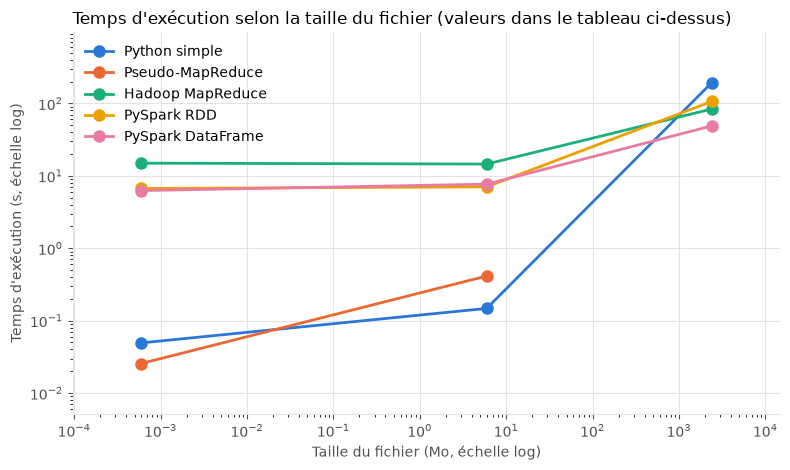

In [67]:
COULEURS = {"Python simple": "#2a78d6", "Pseudo-MapReduce": "#eb6834", "Hadoop MapReduce": "#1baf7a",
            "PySpark RDD": "#eda100", "PySpark DataFrame": "#e87ba4"}
ENCRE, GRILLE = "#52514e", "#e4e3df"

fig, ax = plt.subplots(figsize=(8, 4.8))
for methode, couleur in COULEURS.items():
    s = df[(df["méthode"] == methode) & (df["statut"] == "OK")].sort_values("taille (Mo)")
    ax.plot(s["taille (Mo)"], s["temps (s)"], marker="o", markersize=8, linewidth=2, color=couleur, label=methode)

ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Taille du fichier (Mo, échelle log)", color=ENCRE)
ax.set_ylabel("Temps d'exécution (s, échelle log)", color=ENCRE)
ax.set_title("Temps d'exécution selon la taille du fichier (valeurs dans le tableau ci-dessus)", loc="left", fontsize=12)
ax.grid(True, which="major", color=GRILLE, linewidth=0.8); ax.set_axisbelow(True)
ax.tick_params(colors=ENCRE)
for cote in ("top", "right"):
    ax.spines[cote].set_visible(False)
for cote in ("left", "bottom"):
    ax.spines[cote].set_color(GRILLE)
ax.legend(frameon=False, loc="upper left")
ax.margins(x=0.12, y=0.18)
plt.tight_layout()
plt.show()

## 15. Conclusion de la partie 2

- **Petit fichier** : PySpark répond en **~6 s**, contre **15 s** pour Hadoop et **~0,03 s** pour Python. Spark a lui aussi un **coût fixe** (démarrage de la JVM et de la session), mais il est 10s plus court que Hadoop MapReduce
- **Moyen fichier** : PySpark RDD → **7 s** ; PySpark DataFrame → **6,5 s** ; Hadoop MapReduce → **15s** ; Python simple → **~0,4 s**, Python est 10x plus long qu'avec le petit jeu de données alors que PySpark reste quasi constant
- **Gros fichier** : PySpark RDD → **106 s** ; PySpark DataFrame → **48 s** (2x plus rapide qu'avec les RDD car tous les calculs sont fait directemment dans la JVM et il n'y a aucun appel à Python à faire); Hadoop MapReduce → **83s** ; Python simple → **~200 s**
- **RDD ou DataFrame** : écart : **DataFrame plus de 2x plus rapides que RDD**; il s'explique par le fait que dans les RDDs, les fonctions Python sont traités dans des processus Python séparés, tandis que dans les DataFrames tout est traité directemment dans la JVM.
- **Limite de l'expérience** : tout tourne sur une seule machine ; Spark en mode `local[*]` n'a pas à passer par YARN, contrairement au job Hadoop.

**Bilan** : Sur les petits et moyens fichiers, PySpark (~6,5 s) a un coût fixe plus de deux fois inférieur à celui de Hadoop MapReduce (~15 s), mais reste très loin de Python (moins de 0,5 s) : à cette échelle, aucun outil distribué ne se justifie. Sur le gros fichier (2,4 Go), PySpark DataFrame est la méthode la plus rapide (48 s), soit 2x plus rapide que Hadoop MapReduce (84 s) et près de 5x plus que Python simple (192 s). PySpark RDD (97 s) est en revanche un peu plus lent que Hadoop : le gain apporté par Spark dépend donc de l'API utilisée, et c'est l'API DataFrame qu'il faut privilégier.

## Annexe — Arrêt du cluster

In [68]:
for outil, demon in [("yarn", "nodemanager"), ("yarn", "resourcemanager"), ("hdfs", "datanode"), ("hdfs", "namenode")]:
    sh(outil, "--daemon", "stop", demon, verifier=False)

$ yarn --daemon stop nodemanager
$ yarn --daemon stop resourcemanager
$ hdfs --daemon stop datanode
$ hdfs --daemon stop namenode


## Annexe — Console YARN après l'exécution

![Console YARN](YARN_console.png)

## Annexe — Console SPARK après l'exécution

![Console SPARK](SPARK_console.png)